## Cross Validation (Diabetes set)

In [23]:
# Import necessary libraries for data analysis, visualization, and machine learning

import numpy as np # import numpy library for numerical operations and array manipulations
import matplotlib.pyplot as plt # import matplotlib library for creating visualizations and plots
import pandas as pd # import pandas library for data manipulation and analysis, particularly for working with tabular data
from sklearn.model_selection import train_test_split # import train_test_split function from sklearn to split the dataset into training and testing sets
from sklearn.linear_model import LinearRegression # import LinearRegression class from sklearn to create and train linear regression models
from sklearn.model_selection import cross_val_score # import cross_val_score function from sklearn to perform cross-validation and evaluate model performance
from sklearn.preprocessing import PolynomialFeatures # import PolynomialFeatures class from sklearn to generate polynomial features for regression models
from sklearn.metrics import mean_squared_error # import mean_squared_error function from sklearn to calculate the mean squared error between predicted and actual values

from sklearn import datasets # import datasets module from sklearn to access built-in datasets for machine learning tasks

In [24]:
# Load the diabetes dataset from sklearn's built-in datasets module and separate it into features (X) and target variable (y)

diabetes = datasets.load_diabetes() # Load the diabetes dataset from sklearn's built-in datasets module, which contains data related to diabetes progression and various health metrics, and store it in the variable 'diabetes' for further analysis
print(diabetes.DESCR) # Print the description of the diabetes dataset to provide information about the dataset's structure, features, target variable, and other relevant details for understanding the data and its context
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names) # Convert the features of the diabetes dataset into a pandas DataFrame for easier manipulation and analysis, using the feature names provided in the dataset to label the columns appropriately
y = diabetes.target # Extract the target variable (diabetes progression) from the diabetes dataset and store it in the variable 'y' for further analysis

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [25]:
X.head() # Display the first few rows of the features DataFrame (X) to get an overview of the data and its structure

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [26]:
#Try some feature combinations

selected_features = ['sex', 'bmi', 'bp', 's3', 's5'] # Select a subset of features from the original features DataFrame (X) to focus on specific variables that may be relevant for the analysis, including 'sex', 'bmi', 'bp', 's3', and 's5'
X_subset = X[selected_features].values # Create a new array (X_subset) containing only the selected features from the original features DataFrame (X) by accessing the values of the specified columns, which will be used for further analysis and model training

In [27]:
X_subset.shape # Display the shape of the subset of features (X_subset) to understand the number of samples and features being used for the analysis

(442, 5)

In [28]:
# Create a pandas DataFrame from the subset of features (X_subset) for easier manipulation and analysis, using the selected feature names to label the columns appropriately

X_subset = pd.DataFrame(X_subset, columns=selected_features) # Convert the subset of features (X_subset) back into a pandas DataFrame for easier manipulation and analysis, using the selected feature names to label the columns appropriately
X_subset.head()

,sex,bmi,bp,s3,s5
0,0.050680,0.061696,0.021872,-0.043401,0.019907
1,-0.044642,-0.051474,-0.026328,0.074412,-0.068332
2,0.050680,0.044451,-0.005670,-0.032356,0.002861
3,-0.044642,-0.011595,-0.036656,-0.036038,0.022688
4,-0.044642,-0.036385,0.021872,0.008142,-0.031988


In [29]:
#Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X_subset, y, test_size=0.2, random_state=10) # Split the subset of features (X_subset) and target variable (y) into training and testing sets using sklearn's train_test_split function, with 20% of the data allocated for testing and a random state of 10 for reproducibility

In [30]:
# Evaluate polynomial regression models of different degrees using cross-validation and test set evaluation

degrees = range(1, 6)  # Define a range of polynomial degrees (1 to 5) to evaluate the performance of polynomial regression models with varying complexity
train_mean_scores = [] # Stores cross-validation R2 scores for each degree
test_scores = []       # Stores R2 scores for the test set for each degree
error_train = []       # Stores MSE for the training set for each degree
error_test = []        # Stores MSE for the test set for each degree

# Evaluate each degree by creating a polynomial regression model run cross-validation

for d in degrees: # Loop through each polynomial degree in the defined range to evaluate the performance of polynomial regression models with varying complexity
    
    # Calculate the poly features
    X_train_poly = PolynomialFeatures(d).fit_transform(X_train) # Generate polynomial features of degree d for the training set (X_train) using the PolynomialFeatures class from sklearn, which transforms the original features into a higher-dimensional space to capture non-linear relationships
    X_test_poly = PolynomialFeatures(d).fit_transform(X_test) # Generate polynomial features of degree d for the test set (X_test) using the PolynomialFeatures class from sklearn, which transforms the original features into a higher-dimensional space to capture non-linear relationships
    model = LinearRegression() # Create an instance of the LinearRegression class from sklearn to initialize a linear regression model that will be used for fitting the polynomial features and making predictions
    
    #Perform cross-validation on the training set and get the R2 score as above
    train_scores = cross_val_score(model, X_train_poly, y_train) # Perform cross-validation on the training set (X_train_poly and y_train) using the cross_val_score function from sklearn, which evaluates the model's performance by splitting the data into multiple folds and calculating the R2 score for each fold
    train_score = train_scores.mean() # Calculate the mean R2 score from the cross-validation results to obtain an overall measure of the model's performance on the training set
    train_mean_scores.append(train_score) # Store the mean R2 score for the current polynomial degree in the train_mean_scores list to keep track of the model's performance across different degrees
    
    #Fit the model on the poly training set and score on the poly test set
    model.fit(X_train_poly, y_train) # Fit the linear regression model on the polynomial features of the training set (X_train_poly and y_train) using the fit method, which estimates the model parameters based on the training data
    mse_train = mean_squared_error(model.predict(X_train_poly), y_train) # Calculate the mean squared error (MSE) for the training set by comparing the predicted values from the fitted model (model.predict(X_train_poly)) with the actual target values (y_train) using the mean_squared_error function from sklearn, which measures the average squared difference between predicted and actual values
    error_train.append(mse_train)    # Record MSE for training set by appending the calculated MSE for the current polynomial degree to the error_train list, which keeps track of the model's performance across different degrees
    test_score = model.score(X_test_poly, y_test) # Calculate the R2 score for the test set by evaluating the fitted model on the polynomial features of the test set (X_test_poly and y_test) using the score method, which measures the proportion of variance in the target variable that is explained by the model
    mse_test = mean_squared_error(model.predict(X_test_poly), y_test) # Calculate the mean squared error (MSE) for the test set by comparing the predicted values from the fitted model (model.predict(X_test_poly)) with the actual target values (y_test) using the mean_squared_error function from sklearn, which measures the average squared difference between predicted and actual values
    error_test.append(mse_test)    # Record MSE for test set by appending the calculated MSE for the current polynomial degree to the error_test list, which keeps track of the model's performance across different degrees
    test_scores.append(test_score) # Store the R2 score for the test set by appending the calculated R2 score for the current polynomial degree to the test_scores list, which keeps track of the model's performance across different degrees
    
    #Display the train and test scores for each degree
    print(f"Degree {d}: Train CV Mean R^2 Score = {train_score:.3f}, Test R^2 Score = {test_score:.3f}, TRain MSE = {mse_train:.3f}, Test MSE = {mse_test:.3f}") # Print the results for the current polynomial degree, including the mean R2 score from cross-validation on the training set, the R2 score on the test set, and the mean squared errors for both the training and test sets, formatted to three decimal places for clarity


Degree 1: Train CV Mean R^2 Score = 0.479, Test R^2 Score = 0.521, TRain MSE = 2895.318, Test MSE = 2995.469
Degree 2: Train CV Mean R^2 Score = 0.487, Test R^2 Score = 0.472, TRain MSE = 2644.944, Test MSE = 3302.176
Degree 3: Train CV Mean R^2 Score = 0.327, Test R^2 Score = 0.412, TRain MSE = 2421.176, Test MSE = 3674.640
Degree 4: Train CV Mean R^2 Score = -2.804, Test R^2 Score = 0.254, TRain MSE = 2119.738, Test MSE = 4666.373
Degree 5: Train CV Mean R^2 Score = -231.821, Test R^2 Score = -4.943, TRain MSE = 1404.277, Test MSE = 37150.916


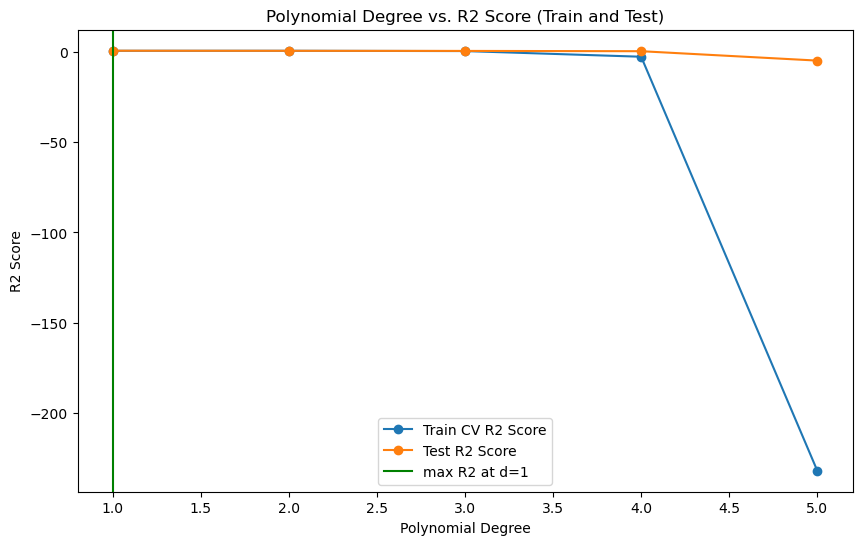

The optimal polynomial degree is 1 with a test R2 score of 0.521.


In [31]:
# Plot results

plt.figure(figsize=(10, 6)) # Create a new figure for the plot with a specified size of 10 inches by 6 inches to ensure clarity and readability of the visualizations
plt.plot(degrees, train_mean_scores, marker='o', label='Train CV R2 Score') # Plot the mean R2 scores from cross-validation on the training set against the polynomial degrees using a line plot with circular markers ('o') and label it as 'Train CV R2 Score' for identification in the legend
plt.plot(degrees, test_scores, marker='o', label='Test R2 Score') # Plot the R2 scores on the test set against the polynomial degrees using a line plot with circular markers ('o') and label it as 'Test R2 Score' for identification in the legend
plt.xlabel('Polynomial Degree') # Set the label for the x-axis of the plot to 'Polynomial Degree' to indicate what the x-axis represents
plt.ylabel('R2 Score') # Set the label for the y-axis of the plot to 'R2 Score' to indicate what the y-axis represents
plt.title('Polynomial Degree vs. R2 Score (Train and Test)') # Set the title for the plot to 'Polynomial Degree vs. R2 Score (Train and Test)' to provide context for the visualization

#Find and display the best degree with the best R2 score on the test set

bestd = degrees[np.argmax(test_scores)] # Find the polynomial degree that yields the highest R2 score on the test set by using numpy's argmax function to identify the index of the maximum value in the test_scores list and retrieving the corresponding degree from the degrees range
plt.axvline(bestd, 0,1, color='g', label="max R2 at d=%d"%bestd) # Add a vertical line to the plot at the best polynomial degree (bestd) to visually indicate the degree that yields the maximum R2 score on the test set, with a green color and a label for identification in the legend
plt.legend() # Add a legend to the plot to display the labels for the plotted lines and the vertical line, allowing for easy identification of the different elements in the visualization
plt.show() # Display the plot to visualize the relationship between polynomial degree and R2 scores for both the training and test sets, along with the vertical line indicating the optimal polynomial degree
print(f"The optimal polynomial degree is {bestd} with a test R2 score of {max(test_scores):.3f}.") # Print a message to the console indicating the optimal polynomial degree (bestd) that yields the highest R2 score on the test set, along with the corresponding maximum R2 score formatted to three decimal places for clarity
